<a href="https://colab.research.google.com/github/0105-yujin/data-structures/blob/main/Week2/DS_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 데이터구조 02강 실습 및 과제
## 알고리즘 복잡도와 Big-O

**과목**: 데이터구조 | **담당교수**: 임화정 | **차시**: 03. 알고리즘 복잡도와 Big-O

본 노트북은 강의에서 다룬 시간 복잡도(O(1), O(n), O(n²))와 탐색 알고리즘(선형 탐색, 이분 탐색)을
직접 코드로 확인하고, 실습 및 과제를 수행하기 위한 템플릿입니다.

---
## 0. 실습 목표

- 입력 크기 n에 따른 알고리즘 실행 시간 변화를 코드로 직접 확인한다.
- O(1), O(n), O(n²) 복잡도의 차이를 실제 실행 시간으로 체감한다.
- 선형 탐색과 이분 탐색을 구현하고, 두 알고리즘의 성능 차이를 비교한다.
- Big-O 이론값과 실제 측정값을 비교 분석하는 과제를 수행한다.

---
## 1. O(1) : 상수 시간 예제

데이터 양과 무관하게 항상 일정한 연산 횟수를 가지는 예시입니다. 배열의 첫 번째 원소에 접근하는 연산은
데이터 크기가 10개든 100만 개든 단 1번의 연산으로 끝납니다.

In [ ]:
def get_first_item(data):
    """O(1) - 상수 시간: 데이터 크기와 무관하게 항상 1번의 연산"""
    return data[0]

import time  #time.perf_counter() 시간 측정을 위한 고성능 카운터

small_data = list(range(10))
large_data = list(range(1_000_000))

start = time.perf_counter()
result_small = get_first_item(small_data)
end = time.perf_counter()
print(f"작은 데이터(n=10) 결과: {result_small}, 소요 시간: {end - start:.10f}s")

start = time.perf_counter()
result_large = get_first_item(large_data)
end = time.perf_counter()
print(f"큰 데이터(n=1,000,000) 결과: {result_large}, 소요 시간: {end - start:.10f}s")

print("\n결론: 데이터 크기가 커져도 실행 시간은 거의 동일함을 확인할 수 있습니다.")

작은 데이터(n=10) 결과: 0, 소요 시간: 0.0000964900s
큰 데이터(n=1,000,000) 결과: 0, 소요 시간: 0.0001433490s

결론: 데이터 크기가 커져도 실행 시간은 거의 동일함을 확인할 수 있습니다.


---
## 2. O(n) : 선형 시간 예제

데이터 크기 n에 정비례하여 연산 횟수가 증가하는 예시입니다. 모든 원소를 한 번씩 순회하는
반복문이 대표적인 O(n) 구조입니다.

In [ ]:
def print_all_items(data):
    """O(n) - 선형 시간: 데이터 크기에 정비례하여 연산 횟수 증가"""
    count = 0
    for item in data:
        count += 1
    return count

import time

for n in [1_000, 10_000, 100_000, 1_000_000]:
    data = list(range(n))
    start = time.perf_counter()
    print_all_items(data) #for문을 몇번 했는지 카운트한 횟수
    end = time.perf_counter()
    print(f"n = {n:>10,}  ->  소요 시간: {end - start:.6f}s")

n =      1,000  ->  소요 시간: 0.000603s
n =     10,000  ->  소요 시간: 0.000383s
n =    100,000  ->  소요 시간: 0.004021s
n =  1,000,000  ->  소요 시간: 0.046452s


---
## 3. O(n²) : 제곱 시간 예제

중첩 반복문으로 인해 n의 제곱에 비례하여 연산 횟수가 폭증하는 예시입니다.
n이 커질수록 실행 시간이 매우 빠르게 증가하므로 테스트 범위를 작게 설정했습니다.

In [ ]:
def count_all_pairs(data):
    """O(n^2) - 제곱 시간: 중첩 루프로 인해 n의 제곱에 비례하여 연산 횟수 증가"""
    count = 0
    for i in data:
        for j in data:
            count += 1
    return count

import time

for n in [100, 500, 1_000, 2_000]:
    data = list(range(n))
    start = time.perf_counter()
    count_all_pairs(data)
    end = time.perf_counter()
    print(f"n = {n:>6,}  ->  연산 횟수: {n*n:>12,}  소요 시간: {end - start:.6f}s")

print("\n주목: n이 2배가 되면(1,000 -> 2,000) 실행 시간은 약 4배로 증가합니다 (n^2 특성).")

n =    100  ->  연산 횟수:       10,000  소요 시간: 0.001172s
n =    500  ->  연산 횟수:      250,000  소요 시간: 0.010997s
n =  1,000  ->  연산 횟수:    1,000,000  소요 시간: 0.039103s
n =  2,000  ->  연산 횟수:    4,000,000  소요 시간: 0.146463s

주목: n이 2배가 되면(1,000 -> 2,000) 실행 시간은 약 4배로 증가합니다 (n^2 특성).


---
## 4. 선형 탐색 (Linear Search) 구현

데이터의 처음부터 끝까지 순차적으로 값을 비교하는 탐색 방식입니다.
- Best Case: O(1) - 첫 번째 원소가 target인 경우
- Worst Case: O(n) - target이 마지막에 있거나 존재하지 않는 경우

In [ ]:
def linear_search(data, target):
    """
    선형 탐색: 데이터를 처음부터 끝까지 순차적으로 확인
    반환값: target의 인덱스, 없으면 -1
    """
    for i in range(len(data)):
        if data[i] == target:
            return i
    return -1

test_data = [4, 2, 9, 7, 1, 5, 8, 3, 6, 0]
print("선형 탐색 결과 (target=7):", linear_search(test_data, 7))
print("선형 탐색 결과 (target=100):", linear_search(test_data, 100))

선형 탐색 결과 (target=7): 3
선형 탐색 결과 (target=100): -1


---
## 5. 이분 탐색 (Binary Search) 구현

정렬된 데이터에서 탐색 범위를 절반씩 좁혀가며 값을 찾는 방식입니다.
- 전제 조건: 데이터가 반드시 정렬되어 있어야 함
- Worst Case: O(log n)

In [ ]:
def binary_search(data, target):
    """
    이분 탐색: 정렬된 데이터에서 탐색 범위를 절반씩 줄여가며 탐색
    반환값: target의 인덱스, 없으면 -1
    """
    left, right = 0, len(data) - 1
    while left <= right: #흐름이 궁금하면 print 넣어 확인
        mid = (left + right) // 2
        if data[mid] == target:
            return mid
        elif data[mid] < target:
            left = mid + 1
        else:
            right = mid - 1
    return -1

sorted_data = sorted(test_data)
print("정렬된 데이터:", sorted_data)
print("이분 탐색 결과 (target=7):", binary_search(sorted_data, 7))
print("이분 탐색 결과 (target=100):", binary_search(sorted_data, 100))

정렬된 데이터: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
이분 탐색 결과 (target=7): 7
이분 탐색 결과 (target=100): -1


---
## 6. 성능 측정 실습 - 데이터 크기별 실행 시간 비교

n을 10부터 1,000,000까지 변화시키며 선형 탐색과 이분 탐색의 실행 시간을 측정합니다.
각 경우 최악의 경우(마지막 원소를 찾는 경우)를 기준으로 측정합니다.

In [ ]:
import time

sizes = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
linear_times = []
binary_times = []

for n in sizes:
    data = list(range(n))   # 이미 정렬된 상태
    target = n - 1           # 최악의 경우: 마지막 원소 탐색

    start = time.perf_counter()
    linear_search(data, target)
    end = time.perf_counter()
    linear_times.append(end - start)

    start = time.perf_counter()
    binary_search(data, target)
    end = time.perf_counter()
    binary_times.append(end - start)

print(f"{'n':>12} | {'선형 탐색(s)':>15} | {'이분 탐색(s)':>15}")
print("-" * 50)
for n, lt, bt in zip(sizes, linear_times, binary_times):
    print(f"{n:>12,} | {lt:>15.8f} | {bt:>15.8f}")

           n |        선형 탐색(s) |        이분 탐색(s)
--------------------------------------------------
          10 |      0.00000365 |      0.00000342
         100 |      0.00000827 |      0.00000244
       1,000 |      0.00009083 |      0.00000498
      10,000 |      0.00097271 |      0.00000645
     100,000 |      0.01198268 |      0.00001998
   1,000,000 |      0.08480240 |      0.00002703


In [ ]:
# @title Colab에서 한글 폰트 설치
!apt-get install -y fonts-nanum
!fc-cache -fv

import matplotlib.font_manager as fm
fm._load_fontmanager(try_read_cache=False)


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 11 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/

In [ ]:
# @title matplotlib 폰트설정
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fm.fontManager.addfont(font_path)

font_name = fm.FontProperties(fname=font_path).get_name()
print(font_name)  # 'NanumGothic' 이 출력되어야 함

plt.rcParams['font.family'] = font_name
plt.rcParams['axes.unicode_minus'] = False # # 음수 눈금의 마이너스 기호를 유니코드 '−' 대신 ASCII '-' (일반 하이픈/마이너스)로 표시



NanumGothic


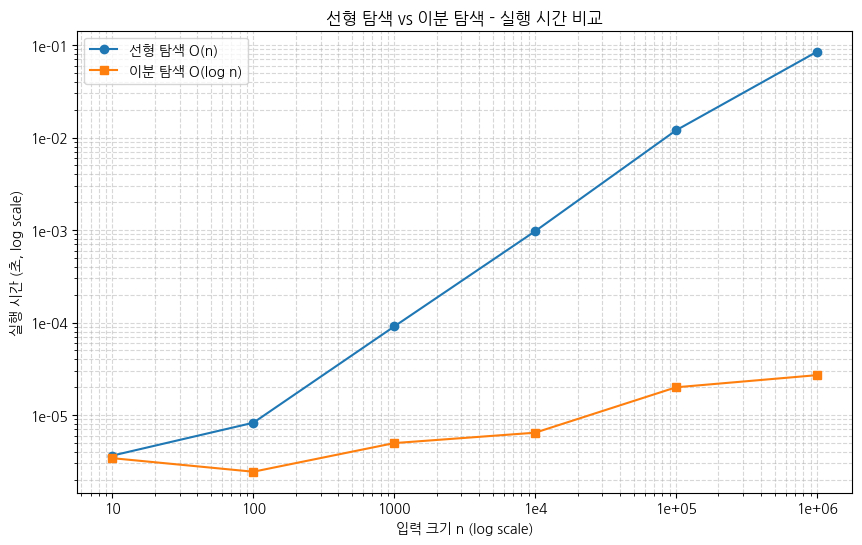

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker #10^{-3} 같은 mathtext를 쓰면 한글 유니코드 − 문자(U+2212) 에러

plt.figure(figsize=(10, 6))
plt.plot(sizes, linear_times, marker='o', label='선형 탐색 O(n)')
plt.plot(sizes, binary_times, marker='s', label='이분 탐색 O(log n)')
plt.xscale('log')
plt.yscale('log')

# 핵심: log scale 기본 mathtext formatter 대신 일반 formatter 사용
ax = plt.gca()
ax.xaxis.set_major_formatter(mticker.LogFormatter(base=10))
ax.yaxis.set_major_formatter(mticker.LogFormatter(base=10))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.yaxis.set_minor_formatter(mticker.NullFormatter())

plt.xlabel('입력 크기 n (log scale)')
plt.ylabel('실행 시간 (초, log scale)')
plt.title('선형 탐색 vs 이분 탐색 - 실행 시간 비교')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.show()

---
## 7. Big-O 이론값과 실제 측정값 비교 분석

이론적인 연산 횟수(선형 탐색은 n, 이분 탐색은 log2 n)와 실제 측정된 실행 시간을 나란히 비교합니다.

In [ ]:
import math

print(f"{'n':>12} | {'이론 O(n)':>13} | {'이론 O(log n)':>13} | {'실제 선형(s)':>10} | {'실제 이분(s)':>10}")
print("-" * 85)
for n, lt, bt in zip(sizes, linear_times, binary_times):
    theoretical_linear = n
    theoretical_binary = math.log2(n) if n > 0 else 0
    print(f"{n:>12,} | {theoretical_linear:>15,} | {theoretical_binary:>15.2f} | {lt:>14.8f} | {bt:>14.8f}")

print("\n분석: 이론적 연산 횟수(O(n), O(log n))의 증가 추세와 실제 측정된 실행 시간의 증가 추세가")
print("유사한 패턴을 보이는지 비교해보세요. (실제 시간은 시스템 환경, 캐시, 오버헤드 등의 영향을 받습니다)")

           n |       이론 O(n) |   이론 O(log n) |   실제 선형(s) |   실제 이분(s)
-------------------------------------------------------------------------------------
          10 |              10 |            3.32 |     0.00000365 |     0.00000342
         100 |             100 |            6.64 |     0.00000827 |     0.00000244
       1,000 |           1,000 |            9.97 |     0.00009083 |     0.00000498
      10,000 |          10,000 |           13.29 |     0.00097271 |     0.00000645
     100,000 |         100,000 |           16.61 |     0.01198268 |     0.00001998
   1,000,000 |       1,000,000 |           19.93 |     0.08480240 |     0.00002703

분석: 이론적 연산 횟수(O(n), O(log n))의 증가 추세와 실제 측정된 실행 시간의 증가 추세가
유사한 패턴을 보이는지 비교해보세요. (실제 시간은 시스템 환경, 캐시, 오버헤드 등의 영향을 받습니다)


---
# 8. 과제 (Assignment)

**과제 가이드라인** (강의자료 16페이지 기준)

- 선형 탐색과 이분 탐색의 실행 시간을 데이터 크기 n의 변화에 따라 측정합니다.
- n = 10 ~ 1,000,000(100만) 범위에서 측정하고, 결과를 표와 그래프로 포함합니다.
- Big-O 이론값과 실제 측정값을 비교 분석합니다.
- 제출 형식: PDF 파일, 제출처: e-Campus, 제출 기한: 다음 주 수업 시작 전까지

           n |        선형 탐색(s) |        이분 탐색(s)
--------------------------------------------------
          10 |      0.00032656 |      0.00000593
         100 |      0.00000777 |      0.00000231
       1,000 |      0.00004936 |      0.00000328
      10,000 |      0.00047615 |      0.00000336
     100,000 |      0.00514907 |      0.00001099
   1,000,000 |      0.06399275 |      0.00002054


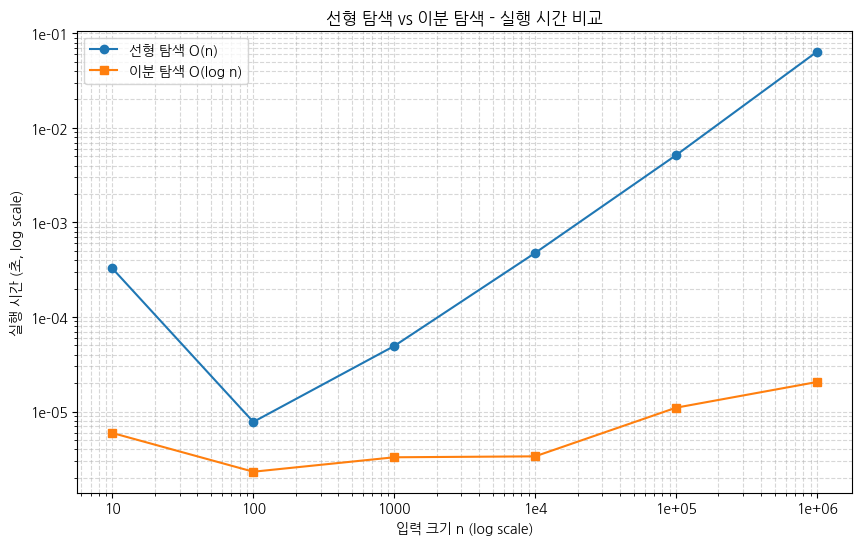

           n |       이론 O(n) |   이론 O(log n) |   실제 선형(s) |   실제 이분(s)
-------------------------------------------------------------------------------------
          10 |              10 |            3.32 |     0.00032656 |     0.00000593
         100 |             100 |            6.64 |     0.00000777 |     0.00000231
       1,000 |           1,000 |            9.97 |     0.00004936 |     0.00000328
      10,000 |          10,000 |           13.29 |     0.00047615 |     0.00000336
     100,000 |         100,000 |           16.61 |     0.00514907 |     0.00001099
   1,000,000 |       1,000,000 |           19.93 |     0.06399275 |     0.00002054

분석: 이론적 연산 횟수(O(n), O(log n))의 증가 추세와 실제 측정된 실행 시간의 증가 추세가
유사한 패턴을 보이는지 비교해보세요. (실제 시간은 시스템 환경, 캐시, 오버헤드 등의 영향을 받습니다)


In [ ]:
# ===== 과제 템플릿 =====
# 아래 TODO 부분을 채워서 과제를 완성하세요.

import time
import random
import matplotlib.pyplot as plt

# TODO 1: n = 10 ~ 1,000,000 범위에서 다양한 n 값을 리스트로 정의하세요.
#          (예: 등비수열로 10, 100, 1000, ... 또는 원하는 간격으로 지정)
assignment_sizes = [10, 100, 1_000, 10_000, 100_000, 1_000_000]  # 예: [10, 100, 1000, 10000, 100000, 1000000]

# TODO 2: 각 n에 대해 선형 탐색과 이분 탐색의 실행 시간을 측정하여
#          아래 리스트에 저장하세요. (최악의 경우를 기준으로 측정 권장)
assignment_linear_times = []
assignment_binary_times = []

# 힌트: for n in assignment_sizes: ... 형태로 위 6번 셀의 코드를 참고하세요.
for n in assignment_sizes:
    data = list(range(n))
    target = n - 1

    start = time.perf_counter()
    linear_search(data, target)
    end = time.perf_counter()
    assignment_linear_times.append(end - start)

    start = time.perf_counter()
    binary_search(data, target)
    end = time.perf_counter()
    assignment_binary_times.append(end - start)

# TODO 3: 측정 결과를 표 형태로 출력하세요.
print(f"{'n':>12} | {'선형 탐색(s)':>15} | {'이분 탐색(s)':>15}")
print("-" * 50)
for n, lt, bt in zip(assignment_sizes, assignment_linear_times, assignment_binary_times):
    print(f"{n:>12,} | {lt:>15.8f} | {bt:>15.8f}")

# TODO 4: 측정 결과를 그래프로 시각화하세요. (matplotlib 사용, x축/y축 log scale 권장)
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.figure(figsize=(10, 6))
plt.plot(assignment_sizes, assignment_linear_times, marker='o', label='선형 탐색 O(n)')
plt.plot(assignment_sizes, assignment_binary_times, marker='s', label='이분 탐색 O(log n)')
plt.xscale('log')
plt.yscale('log')

ax = plt.gca()
ax.xaxis.set_major_formatter(mticker.LogFormatter(base=10))
ax.yaxis.set_major_formatter(mticker.LogFormatter(base=10))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.yaxis.set_minor_formatter(mticker.NullFormatter())

plt.xlabel('입력 크기 n (log scale)')
plt.ylabel('실행 시간 (초, log scale)')
plt.title('선형 탐색 vs 이분 탐색 - 실행 시간 비교')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.show()
# TODO 5: Big-O 이론값(O(n), O(log n))과 실제 측정값을 비교하는 코드를 작성하세요.
import math

print(f"{'n':>12} | {'이론 O(n)':>13} | {'이론 O(log n)':>13} | {'실제 선형(s)':>10} | {'실제 이분(s)':>10}")
print("-" * 85)
for n, lt, bt in zip(assignment_sizes, assignment_linear_times, assignment_binary_times):
    theoretical_linear = n
    theoretical_binary = math.log2(n) if n > 0 else 0
    print(f"{n:>12,} | {theoretical_linear:>15,} | {theoretical_binary:>15.2f} | {lt:>14.8f} | {bt:>14.8f}")

print("\n분석: 이론적 연산 횟수(O(n), O(log n))의 증가 추세와 실제 측정된 실행 시간의 증가 추세가")
print("유사한 패턴을 보이는지 비교해보세요. (실제 시간은 시스템 환경, 캐시, 오버헤드 등의 영향을 받습니다)")

---
## 9. 과제 결과 분석 (서술형 답안 작성)

아래 질문에 대한 답을 직접 작성해 보세요. 이 마크다운 셀을 더블클릭하여 수정할 수 있습니다.

**1. 선형 탐색과 이분 탐색의 실행 시간은 n이 증가함에 따라 어떻게 변화했습니까?**

선형탐색 : n이 커질수록 실행시간도 정직하게 비례하여 증가하였다.
이분탐색 : n이 100만까지 늘어나도 실행시간은 거의 늘어나지 않고 유지되었다.

**2. 이론적인 Big-O 복잡도와 실제 측정된 실행 시간의 증가 추세가 일치했습니까? 차이가 있다면 그 이유는 무엇일까요?**

일치여부 : n=100 이후부턴 선형 탐색은 일정한 직선, 이분탐색은 완만한 곡선을 그리며 이론과 일치하였다.
차이원인 : n=10구간의 일시적인 시간 증가는 파이썬 첫 실행 지연 및 함수 호출 오버헤드 때문이다.

**3. 실무에서 반복 탐색이 필요한 경우, 정렬 비용을 고려했을 때 어떤 탐색 방법을 선택해야 할까요?**

한두번만 찾을 때는 선형탐색을 하는 것이 낫고, 여러 번 계속 찾을 시엔 처음에 한 번 정렬해두고 매번 빠른 이분 탐색을 반복하는 것이 훨씬 유리하다.

---
## 제출 안내

- 보고서 형식: 이파일 그대로 제출
- 제출처: e-Campus
- 제출 기한: 9/20 18시까지 제출